# Understanding modern activation functions

**AI 4200 Deep Learning.** Companion to the lecture *Understanding modern activation functions*, which follows one idea from the perceptron to today's large language models: Heaviside step → sigmoid → ReLU → SiLU → GLU → SwiGLU → bilinear → mixture of experts. Each section below reproduces the plots and numbers on one slide (or a group of slides), in lecture order.

**To run it:** numpy, scipy, pandas and matplotlib (all preinstalled on Colab). No data download and no GPU; the whole notebook runs in a few seconds on a CPU.

**Where the numbers come from:** everything is computed here, except a few values that are flagged where they appear: depth limits given by the instructor, results quoted from papers, and illustrative values on the mixture-of-experts slides.

**Notation.** ŷ is a pre-activation (Ŷ = XWᵀ for a batch), p̂ is the activation output, H is the Heaviside step, σ the logistic sigmoid and Φ the standard normal CDF. In code: `y_hat` and `p_hat`. The example input used throughout the deck is **ŷ = [−3, −1, 0, 1, 3]**.

## Setup: the activation functions and a plotting helper

Every activation in the lecture is defined once here as a vectorized numpy function, together with its derivative ∂p̂/∂ŷ. They work on a single number or a whole array. The plotting helpers give every figure the same look as the slides.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import norm

# Slide colours
BLUE = "#2557D6"
ORANGE = "#C2510F"
INK = "#16181D"
GREY = "#8E94A0"

EXAMPLE_Y_HAT = np.array([-3.0, -1.0, 0.0, 1.0, 3.0])


def identity(y_hat):
    """The ungated stream ŷ, used as the dashed reference in several plots."""
    return y_hat


def heaviside(y_hat):
    """Heaviside step H(ŷ): 1 where ŷ > 0, else 0 (so H(0) = 0)."""
    return np.where(y_hat > 0, 1.0, 0.0)


def sigmoid(y_hat):
    """Logistic sigmoid σ(ŷ) = 1 / (1 + e^(−ŷ))."""
    return 1.0 / (1.0 + np.exp(-y_hat))


def sigmoid_grad(y_hat):
    """Derivative σ′(ŷ) = σ(ŷ)(1 − σ(ŷ)), at most 0.25."""
    s = sigmoid(y_hat)
    return s * (1.0 - s)


def relu(y_hat):
    """ReLU(ŷ) = max(0, ŷ) = ŷ · H(ŷ)."""
    return np.maximum(0.0, y_hat)


def relu_grad(y_hat):
    """Derivative of ReLU: H(ŷ). The undefined value at 0 is taken as 0, as in PyTorch."""
    return heaviside(y_hat)


def silu(y_hat):
    """SiLU (Swish) = ŷ · σ(ŷ): the identity gated by a sigmoid."""
    return y_hat * sigmoid(y_hat)


def silu_grad(y_hat):
    """Derivative of SiLU by the product rule: gate term σ(ŷ) plus slope term ŷ · σ′(ŷ)."""
    return sigmoid(y_hat) + y_hat * sigmoid_grad(y_hat)


def normal_cdf(y_hat):
    """Standard normal CDF Φ(ŷ), the gate used by GELU."""
    return norm.cdf(y_hat)


def gelu(y_hat):
    """GELU = ŷ · Φ(ŷ) (exact form, not the tanh approximation)."""
    return y_hat * normal_cdf(y_hat)

In [2]:
def style_axes(ax, xlim, ylim, xticks, yticks, title, ylabel="p̂"):
    """Apply the slide look: fixed ranges and ticks, zero axes, light grid."""
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_xticks(xticks)
    ax.set_yticks(yticks)
    ax.axhline(0, color="#4E5360", lw=0.8)
    ax.axvline(0, color="#4E5360", lw=0.8)
    ax.grid(True, color="#ECEEF1")
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("ŷ")
    ax.set_ylabel(ylabel)


def plot_curve(ax, f, x_min, x_max, color, label=None, dashed=False):
    """Plot a smooth function f on [x_min, x_max]."""
    y_hat = np.linspace(x_min, x_max, 400)
    ax.plot(y_hat, f(y_hat), color=color, lw=2.4, ls="--" if dashed else "-", label=label)


def plot_step(ax, x_min, x_max, color, label=None, dashed=False, low=0.0, high=1.0):
    """Plot a step from `low` to `high` at ŷ = 0; filled dot = value at 0, open dot = limit from the right."""
    style = "--" if dashed else "-"
    ax.plot([x_min, 0], [low, low], color=color, lw=2.4, ls=style, label=label)
    ax.plot([0, x_max], [high, high], color=color, lw=2.4, ls=style)
    if not dashed:
        ax.plot([0], [low], "o", color=color, ms=6)
        ax.plot([0], [high], "o", mfc="white", mec=color, mew=2, ms=6)


def plot_zero_with_gap(ax, x_min, x_max, gap, color, label=None):
    """Plot the constant 0 with a gap around ŷ = 0, where the derivative of a step is undefined."""
    ax.plot([x_min, -gap], [0, 0], color=color, lw=2.4, label=label)
    ax.plot([gap, x_max], [0, 0], color=color, lw=2.4)
    ax.annotate("undefined at 0", (0.1, 0.1), color="#8A3A0A", fontsize=9)

## Example values used across the deck: ŷ = −3, −1, 0, 1, 3

The values of σ, ReLU and SiLU and their derivatives at the five example inputs. The SiLU′ column is the table on *Why is SiLU better?* (slide 13), and σ(0) = 0.5, σ′(0) = 0.25 appear on the sigmoid slide. The last column is the slope term of SiLU′ = σ(ŷ) + ŷ · σ′(ŷ) from the product-rule slides; notice that it is negative for ŷ < 0, which is what lets SiLU′ dip below zero.

In [3]:
example_table = pd.DataFrame({
    "σ": sigmoid(EXAMPLE_Y_HAT),
    "σ′": sigmoid_grad(EXAMPLE_Y_HAT),
    "ReLU": relu(EXAMPLE_Y_HAT),
    "ReLU′": relu_grad(EXAMPLE_Y_HAT),
    "SiLU": silu(EXAMPLE_Y_HAT),
    "SiLU′": silu_grad(EXAMPLE_Y_HAT),
    "slope term ŷ·σ′": EXAMPLE_Y_HAT * sigmoid_grad(EXAMPLE_Y_HAT),
}, index=pd.Index(EXAMPLE_Y_HAT, name="ŷ"))
example_table.round(3)

,σ,σ′,ReLU,ReLU′,SiLU,SiLU′,slope term ŷ·σ′
ŷ,,,,,,,
-3.0,0.047,0.045,0.0,0.0,-0.142,-0.088,-0.136
-1.0,0.269,0.197,0.0,0.0,-0.269,0.072,-0.197
0.0,0.500,0.250,0.0,0.0,0.000,0.500,0.000
1.0,0.731,0.197,1.0,1.0,0.731,0.928,0.197
3.0,0.953,0.045,3.0,1.0,2.858,1.088,0.136


SiLU is not monotonic: it has a minimum on the negative side, and its derivative overshoots 1 and undershoots 0. We find these on a fine grid.

In [4]:
y_grid = np.linspace(-5, 5, 100001)

silu_values = silu(y_grid)
i_min = silu_values.argmin()
print(f"SiLU minimum:  ŷ = {y_grid[i_min]:.3f},  p̂ = {silu_values[i_min]:.3f}")

silu_slopes = silu_grad(y_grid)
i_max = silu_slopes.argmax()
i_min = silu_slopes.argmin()
print(f"SiLU′ maximum: {silu_slopes[i_max]:.4f} at ŷ = {y_grid[i_max]:.4f}")
print(f"SiLU′ minimum: {silu_slopes[i_min]:.4f} at ŷ = {y_grid[i_min]:.4f}")

SiLU minimum:  ŷ = -1.278,  p̂ = -0.278
SiLU′ maximum: 1.0998 at ŷ = 2.3994
SiLU′ minimum: -0.0998 at ŷ = -2.3994


## Slide 2 · The perceptron's Heaviside step

The step p̂ = H(ŷ) and its derivative, which is 0 everywhere it exists. By the chain rule ∂L/∂ŷ = ∂L/∂p̂ · 0 = 0, so no gradient reaches the weights.

*Instructor-supplied:* the slide's "max depth, FFN without residuals: **1 layer**" is not computed.

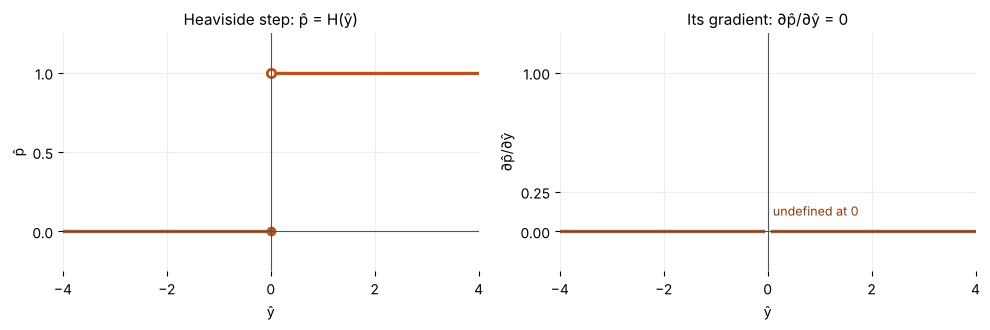

H at the example points: [0. 0. 0. 1. 1.]


In [5]:
fig, (ax_f, ax_g) = plt.subplots(1, 2, figsize=(10, 3.4))

plot_step(ax_f, -4, 4, ORANGE)
style_axes(ax_f, (-4, 4), (-0.25, 1.25), [-4, -2, 0, 2, 4], [0, 0.5, 1], "Heaviside step: p̂ = H(ŷ)")

plot_zero_with_gap(ax_g, -4, 4, gap=0.08, color=ORANGE)
style_axes(ax_g, (-4, 4), (-0.25, 1.25), [-4, -2, 0, 2, 4], [0, 0.25, 1],
           "Its gradient: ∂p̂/∂ŷ = 0", ylabel="∂p̂/∂ŷ")

plt.tight_layout()
plt.show()
print("H at the example points:", heaviside(EXAMPLE_Y_HAT))

## Slide 3 · Sigmoid: a differentiable step

The sigmoid is a smooth version of the step (dashed), so it has a usable gradient. But σ′ never exceeds 0.25, so every sigmoid layer shrinks the back-propagated gradient by at least 4×; the last line shows the best case through ten layers.

*Instructor-supplied:* "≈ 10 layers (quasi-linear region)".

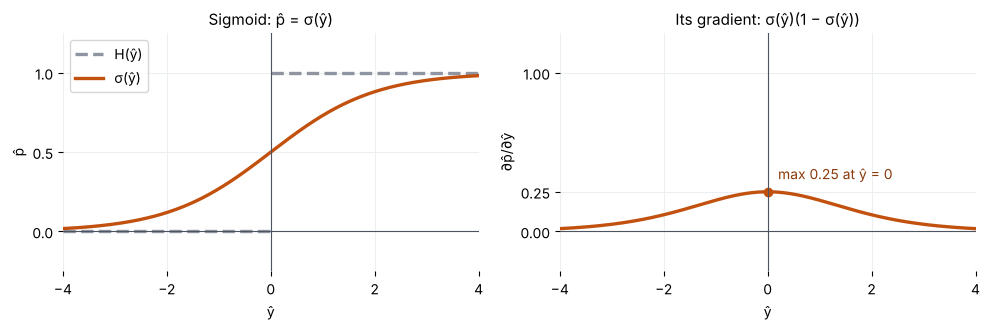

σ(0)  = 0.5
σ′(0) = 0.25  -> each layer multiplies the gradient by at most 1/4
0.25 ** 10 = 9.5367431640625e-07  (best case through ten sigmoid layers)


In [6]:
fig, (ax_f, ax_g) = plt.subplots(1, 2, figsize=(10, 3.4))

plot_step(ax_f, -4, 4, GREY, label="H(ŷ)", dashed=True)
plot_curve(ax_f, sigmoid, -4, 4, ORANGE, label="σ(ŷ)")
style_axes(ax_f, (-4, 4), (-0.25, 1.25), [-4, -2, 0, 2, 4], [0, 0.5, 1], "Sigmoid: p̂ = σ(ŷ)")
ax_f.legend(loc="upper left")

plot_curve(ax_g, sigmoid_grad, -4, 4, ORANGE)
ax_g.plot([0], [sigmoid_grad(0.0)], "o", color=ORANGE)
ax_g.annotate("max 0.25 at ŷ = 0", (0.2, 0.33), color="#8A3A0A")
style_axes(ax_g, (-4, 4), (-0.25, 1.25), [-4, -2, 0, 2, 4], [0, 0.25, 1],
           "Its gradient: σ(ŷ)(1 − σ(ŷ))", ylabel="∂p̂/∂ŷ")

plt.tight_layout()
plt.show()

print("σ(0)  =", sigmoid(0.0))
print("σ′(0) =", sigmoid_grad(0.0), " -> each layer multiplies the gradient by at most 1/4")
print("0.25 ** 10 =", 0.25 ** 10, " (best case through ten sigmoid layers)")

## Slide 4 · ReLU: a gradient of exactly 1

For ŷ > 0 ReLU passes the gradient through unchanged (1, compared with the sigmoid's best case of 0.25, dashed), which is what makes deep networks trainable.

*Instructor-supplied:* "≈ 50 layers".

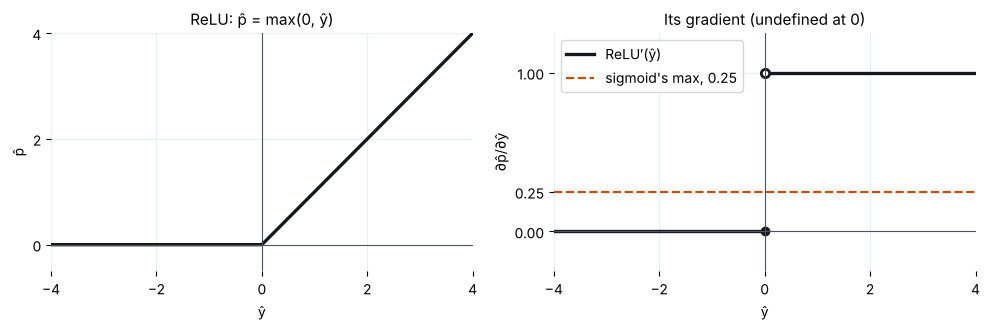

ReLU′ at the example points: [0. 0. 0. 1. 1.]


In [7]:
fig, (ax_f, ax_g) = plt.subplots(1, 2, figsize=(10, 3.4))

plot_curve(ax_f, relu, -4, 4, INK)
style_axes(ax_f, (-4, 4), (-0.5, 4), [-4, -2, 0, 2, 4], [0, 2, 4], "ReLU: p̂ = max(0, ŷ)")

plot_step(ax_g, -4, 4, INK, label="ReLU′(ŷ)")
ax_g.axhline(sigmoid_grad(0.0), color=ORANGE, ls="--", lw=1.6, label="sigmoid's max, 0.25")
style_axes(ax_g, (-4, 4), (-0.25, 1.25), [-4, -2, 0, 2, 4], [0, 0.25, 1],
           "Its gradient (undefined at 0)", ylabel="∂p̂/∂ŷ")
ax_g.legend(loc="upper left")

plt.tight_layout()
plt.show()
print("ReLU′ at the example points:", relu_grad(EXAMPLE_Y_HAT))

## Slides 5–6 · Can you build ReLU from these two? / ReLU is a gated identity

ReLU is the identity ŷ multiplied by the step H(ŷ): the step decides *whether* a value passes, the identity decides *what* passes.

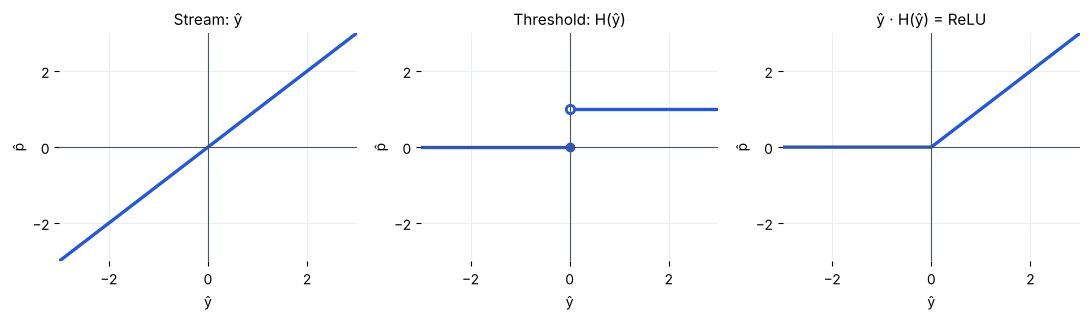

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))

plot_curve(axes[0], identity, -3, 3, BLUE)
style_axes(axes[0], (-3, 3), (-3, 3), [-2, 0, 2], [-2, 0, 2], "Stream: ŷ")

plot_step(axes[1], -3, 3, BLUE)
style_axes(axes[1], (-3, 3), (-3, 3), [-2, 0, 2], [-2, 0, 2], "Threshold: H(ŷ)")

plot_curve(axes[2], relu, -3, 3, BLUE)
style_axes(axes[2], (-3, 3), (-3, 3), [-2, 0, 2], [-2, 0, 2], "ŷ · H(ŷ) = ReLU")

plt.tight_layout()
plt.show()

## Slide 7 · The threshold is back, so why is it fine now?

Top row: the forward pass ŷ × H(ŷ). Bottom row: the derivatives. By the product rule ∂p̂/∂ŷ = H(ŷ) · 1 + ŷ · 0 = H(ŷ). The step's zero derivative drops out, and the gradient flows through the identity.

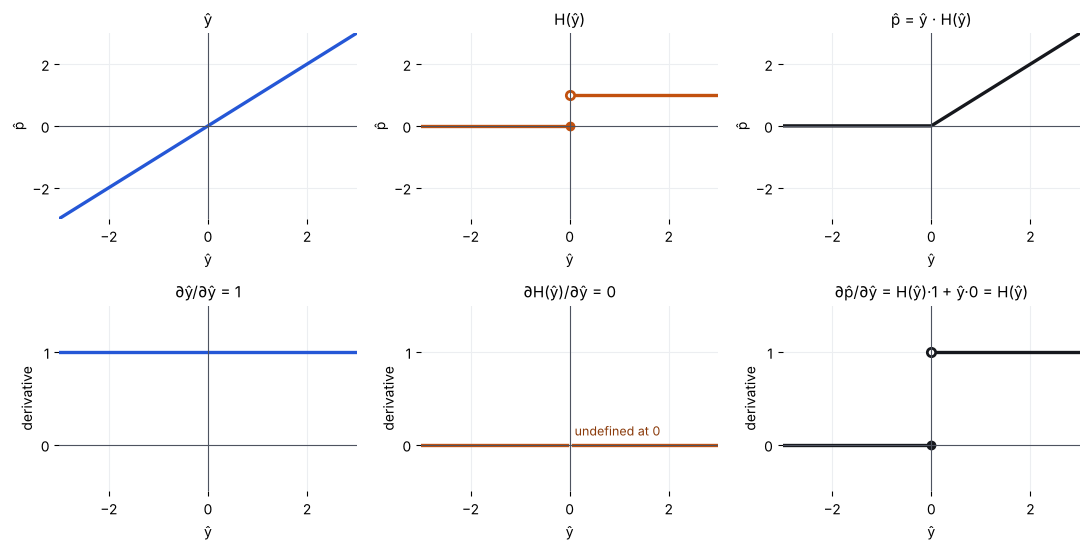

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6))
ticks = [-2, 0, 2]

# forward row
plot_curve(axes[0, 0], identity, -3, 3, BLUE)
style_axes(axes[0, 0], (-3, 3), (-3, 3), ticks, ticks, "ŷ")
plot_step(axes[0, 1], -3, 3, ORANGE)
style_axes(axes[0, 1], (-3, 3), (-3, 3), ticks, ticks, "H(ŷ)")
plot_curve(axes[0, 2], relu, -3, 3, INK)
style_axes(axes[0, 2], (-3, 3), (-3, 3), ticks, ticks, "p̂ = ŷ · H(ŷ)")

# gradient row
plot_curve(axes[1, 0], np.ones_like, -3, 3, BLUE)
style_axes(axes[1, 0], (-3, 3), (-0.5, 1.5), ticks, [0, 1], "∂ŷ/∂ŷ = 1", ylabel="derivative")
plot_zero_with_gap(axes[1, 1], -3, 3, gap=0.06, color=ORANGE)
style_axes(axes[1, 1], (-3, 3), (-0.5, 1.5), ticks, [0, 1], "∂H(ŷ)/∂ŷ = 0", ylabel="derivative")
plot_step(axes[1, 2], -3, 3, INK)
style_axes(axes[1, 2], (-3, 3), (-0.5, 1.5), ticks, [0, 1], "∂p̂/∂ŷ = H(ŷ)·1 + ŷ·0 = H(ŷ)", ylabel="derivative")

plt.tight_layout()
plt.show()

## Slides 8–10 · Gated identity: forward pass, backward pass, each gate sees only its own unit

Diagrams only. The general rule they show, p̂ = ŷ · g(ŷ) ⇒ ∂p̂/∂ŷ = g(ŷ) + ŷ · g′(ŷ), is exactly how `silu_grad` is written in the setup cell (gate term plus slope term).

## Slide 11 · What if the gate were a sigmoid?

Replace the hard gate H by the soft gate σ (step dashed for comparison). The gated identity becomes SiLU = ŷ · σ(ŷ), a smooth ReLU (dashed) that dips slightly below zero for negative ŷ.

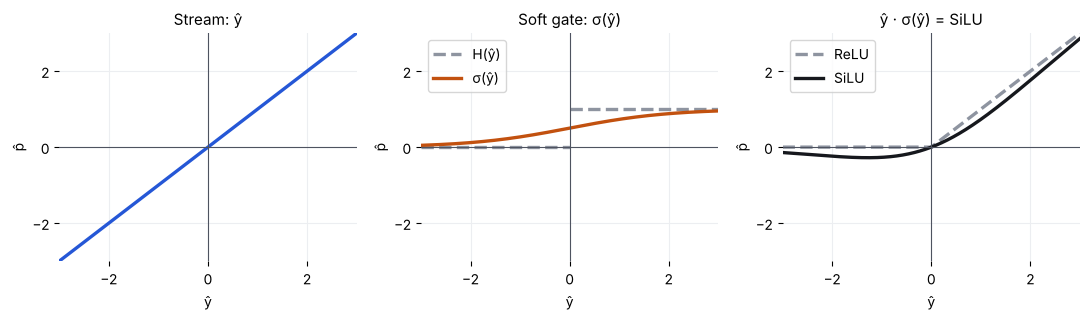

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
ticks = [-2, 0, 2]

plot_curve(axes[0], identity, -3, 3, BLUE)
style_axes(axes[0], (-3, 3), (-3, 3), ticks, ticks, "Stream: ŷ")

plot_step(axes[1], -3, 3, GREY, label="H(ŷ)", dashed=True)
plot_curve(axes[1], sigmoid, -3, 3, ORANGE, label="σ(ŷ)")
style_axes(axes[1], (-3, 3), (-3, 3), ticks, ticks, "Soft gate: σ(ŷ)")
axes[1].legend(loc="upper left")

plot_curve(axes[2], relu, -3, 3, GREY, label="ReLU", dashed=True)
plot_curve(axes[2], silu, -3, 3, INK, label="SiLU")
style_axes(axes[2], (-3, 3), (-3, 3), ticks, ticks, "ŷ · σ(ŷ) = SiLU")
axes[2].legend(loc="upper left")

plt.tight_layout()
plt.show()

## Slide 12 · Why is SiLU an improvement on ReLU?

The discussion question: the same identity, two different gates. Look at the negative side before reading the next slide.

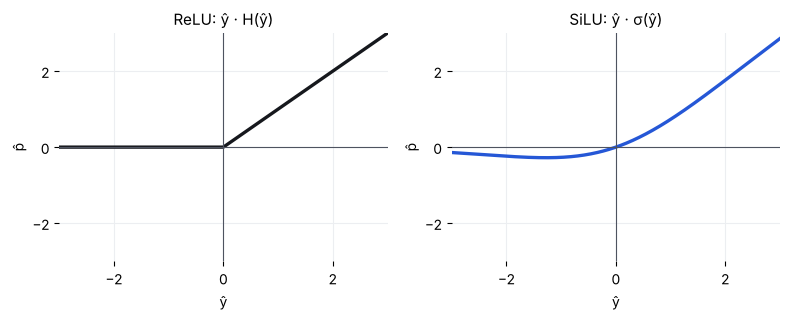

In [11]:
fig, (ax_relu, ax_silu) = plt.subplots(1, 2, figsize=(8, 3.3))
ticks = [-2, 0, 2]

plot_curve(ax_relu, relu, -3, 3, INK)
style_axes(ax_relu, (-3, 3), (-3, 3), ticks, ticks, "ReLU: ŷ · H(ŷ)")

plot_curve(ax_silu, silu, -3, 3, BLUE)
style_axes(ax_silu, (-3, 3), (-3, 3), ticks, ticks, "SiLU: ŷ · σ(ŷ)")

plt.tight_layout()
plt.show()

## Slide 13 · Why is SiLU better? (ReLU vs SiLU: the negative side)

Top: the two activations. Bottom: their derivatives, with the ŷ < 0 region shaded. ReLU′ is exactly 0 there (a "dead" unit gets no gradient), while SiLU′ stays non-zero, and the dots are the values in the slide's table.

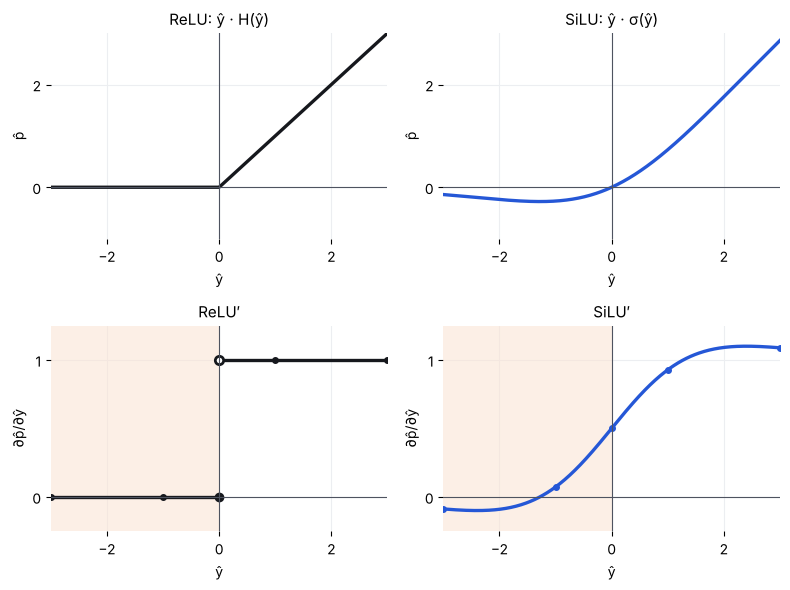

ŷ,3.0,1.0,0.0,-1.0,-3.0
ReLU′,1.000,1.000,0.0,0.000,0.000
SiLU′,1.088,0.928,0.5,0.072,-0.088


In [12]:
fig, axes = plt.subplots(2, 2, figsize=(8, 6))
ticks = [-2, 0, 2]

plot_curve(axes[0, 0], relu, -3, 3, INK)
style_axes(axes[0, 0], (-3, 3), (-1, 3), ticks, [0, 2], "ReLU: ŷ · H(ŷ)")
plot_curve(axes[0, 1], silu, -3, 3, BLUE)
style_axes(axes[0, 1], (-3, 3), (-1, 3), ticks, [0, 2], "SiLU: ŷ · σ(ŷ)")

for ax in axes[1]:
    ax.axvspan(-3, 0, color="#FBE3D2", alpha=0.55, lw=0)
plot_step(axes[1, 0], -3, 3, INK)
axes[1, 0].plot(EXAMPLE_Y_HAT, relu_grad(EXAMPLE_Y_HAT), "o", color=INK, ms=4)
style_axes(axes[1, 0], (-3, 3), (-0.25, 1.25), ticks, [0, 1], "ReLU′", ylabel="∂p̂/∂ŷ")
plot_curve(axes[1, 1], silu_grad, -3, 3, BLUE)
axes[1, 1].plot(EXAMPLE_Y_HAT, silu_grad(EXAMPLE_Y_HAT), "o", color=BLUE, ms=4)
style_axes(axes[1, 1], (-3, 3), (-0.25, 1.25), ticks, [0, 1], "SiLU′", ylabel="∂p̂/∂ŷ")

plt.tight_layout()
plt.show()

# The slide's table lists ŷ from 3 down to −3
slide_order = EXAMPLE_Y_HAT[::-1]
pd.DataFrame({"ReLU′": relu_grad(slide_order), "SiLU′": silu_grad(slide_order)},
             index=pd.Index(slide_order, name="ŷ")).T.round(3)

## Slide 14 · The gated-identity family

Left: three gates, H (hard), σ and Φ (soft). Right: the activations ŷ · g(ŷ) they produce (ReLU, SiLU, GELU), with the identity dashed and each activation's mean for ŷ ~ N(0, 1) dotted. A non-zero mean shifts the next layer's input, so the table compares E[p̂] and the fraction of the output's power E[p̂²] that is just that mean. The expectations are integrals against the normal density, computed here as a Riemann sum on a fine grid.

In [13]:
# E[f(ŷ)] for ŷ ~ N(0, 1): Riemann sum on [−12, 12]; the density is negligible outside
y_grid = np.linspace(-12, 12, 400001)
density = norm.pdf(y_grid)
dy = y_grid[1] - y_grid[0]


def gaussian_mean(values):
    """Approximate E[f(ŷ)] for ŷ ~ N(0, 1) from f evaluated on y_grid."""
    return (values * density).sum() * dy


activations = {
    "ŷ, no gate": y_grid,
    "σ(ŷ) alone": sigmoid(y_grid),
    "ReLU": relu(y_grid),
    "GELU": gelu(y_grid),
    "SiLU": silu(y_grid),
}

rows = []
for name, p_hat in activations.items():
    mean = gaussian_mean(p_hat)
    mean_square = gaussian_mean(p_hat ** 2)
    rows.append({"activation": name, "E[p̂]": mean, "E[p̂²]": mean_square,
                 "E[p̂]² / E[p̂²]": mean ** 2 / mean_square})

gate_means = pd.DataFrame(rows).set_index("activation")
gate_means.round(3)

,E[p̂],E[p̂²],E[p̂]² / E[p̂²]
activation,,,
"ŷ, no gate",0.000,1.000,0.000
σ(ŷ) alone,0.500,0.293,0.852
ReLU,0.399,0.500,0.318
GELU,0.282,0.425,0.187
SiLU,0.207,0.356,0.120


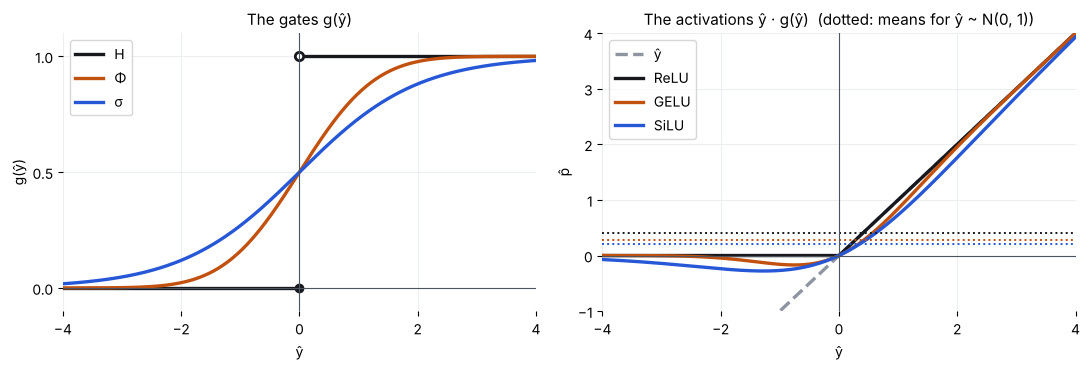

In [14]:
fig, (ax_gates, ax_acts) = plt.subplots(1, 2, figsize=(11, 3.8))

plot_step(ax_gates, -4, 4, INK, label="H")
plot_curve(ax_gates, normal_cdf, -4, 4, ORANGE, label="Φ")
plot_curve(ax_gates, sigmoid, -4, 4, BLUE, label="σ")
style_axes(ax_gates, (-4, 4), (-0.1, 1.1), [-4, -2, 0, 2, 4], [0, 0.5, 1], "The gates g(ŷ)", ylabel="g(ŷ)")
ax_gates.legend(loc="upper left")

plot_curve(ax_acts, identity, -4, 4, GREY, label="ŷ", dashed=True)
plot_curve(ax_acts, relu, -4, 4, INK, label="ReLU")
plot_curve(ax_acts, gelu, -4, 4, ORANGE, label="GELU")
plot_curve(ax_acts, silu, -4, 4, BLUE, label="SiLU")
for name, color in [("ReLU", INK), ("GELU", ORANGE), ("SiLU", BLUE)]:
    ax_acts.axhline(gate_means.loc[name, "E[p̂]"], color=color, ls=":", lw=1.4)
style_axes(ax_acts, (-4, 4), (-1, 4), [-4, -2, 0, 2, 4], [-1, 0, 1, 2, 3, 4],
           "The activations ŷ · g(ŷ)  (dotted: means for ŷ ~ N(0, 1))")
ax_acts.legend(loc="upper left")

plt.tight_layout()
plt.show()

## Slide 15 · These gates only look at one feature

The Jacobian ∂P̂/∂Ŷ at ŷ = [−3, −1, 0, 1, 3]. For SiLU (and every activation so far) output i depends only on input i, so the Jacobian is diagonal, with SiLU′(ŷₖ) on the diagonal. Softmax mixes all inputs, so its Jacobian is dense: p̂ᵢ(1 − p̂ᵢ) on the diagonal and −p̂ᵢp̂ⱼ off it.

softmax p̂ = [0.002 0.015 0.041 0.112 0.829]

SiLU Jacobian (rows p̂ᵢ, columns ŷⱼ):
            ŷ=-3      ŷ=-1       ŷ=0       ŷ=1       ŷ=3
p̂1       -0.088         0         0         0         0
p̂2            0     0.072         0         0         0
p̂3            0         0     0.500         0         0
p̂4            0         0         0     0.928         0
p̂5            0         0         0         0     1.088

Softmax Jacobian (rows p̂ᵢ, columns ŷⱼ):
            ŷ=-3      ŷ=-1       ŷ=0       ŷ=1       ŷ=3
p̂1        0.002  -3.1e-05  -8.5e-05  -2.3e-04    -0.002
p̂2     -3.1e-05     0.015  -6.3e-04    -0.002    -0.013
p̂3     -8.5e-05  -6.3e-04     0.040    -0.005    -0.034
p̂4     -2.3e-04    -0.002    -0.005     0.100    -0.093
p̂5       -0.002    -0.013    -0.034    -0.093     0.142


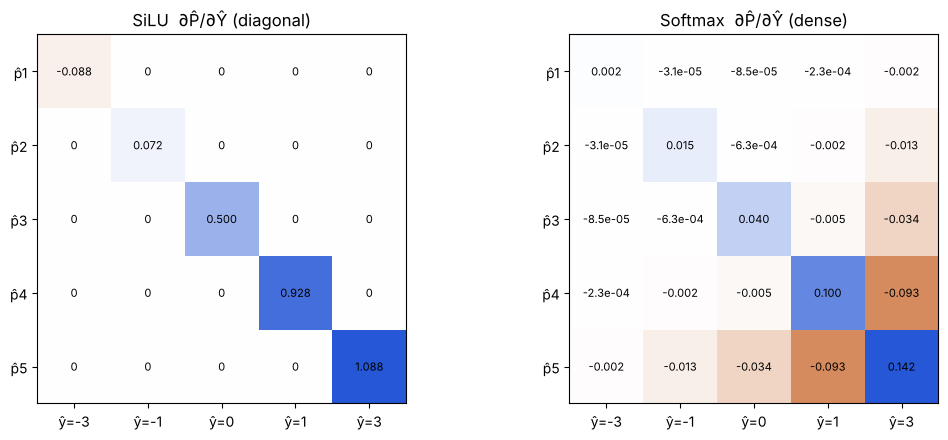

In [15]:
def softmax(y_hat):
    """Softmax; subtracting the max does not change the result but avoids overflow."""
    exp_shifted = np.exp(y_hat - y_hat.max())
    return exp_shifted / exp_shifted.sum()


def format_entry(value):
    """Three decimals, scientific notation below 0.001, and exact zeros shown as 0."""
    if value == 0:
        return "0"
    if abs(value) < 0.001:
        return f"{value:.1e}"
    return f"{value:.3f}"


def print_matrix(matrix, row_labels, col_labels):
    """Print a matrix with labelled rows and columns using format_entry."""
    print(" " * 6 + "".join(f"{label:>10}" for label in col_labels))
    for label, row in zip(row_labels, matrix):
        print(f"{label:<6}" + "".join(f"{format_entry(v):>10}" for v in row))


def plot_jacobian(ax, matrix, row_labels, col_labels, title):
    """Heatmap of a Jacobian: blue positive, orange negative, white zero."""
    limit = np.abs(matrix).max()
    cmap = LinearSegmentedColormap.from_list("slide", [ORANGE, "white", BLUE])
    ax.imshow(matrix, cmap=cmap, vmin=-limit, vmax=limit)
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax.text(j, i, format_entry(matrix[i, j]), ha="center", va="center", fontsize=8)
    ax.set_xticks(range(len(col_labels)), col_labels)
    ax.set_yticks(range(len(row_labels)), row_labels)
    ax.set_title(title)


y_hat = EXAMPLE_Y_HAT
silu_jacobian = np.diag(silu_grad(y_hat))
p_hat = softmax(y_hat)
softmax_jacobian = np.diag(p_hat) - np.outer(p_hat, p_hat)

row_labels = [f"p̂{i + 1}" for i in range(len(y_hat))]
col_labels = [f"ŷ={v:g}" for v in y_hat]
print("softmax p̂ =", p_hat.round(3))
print("\nSiLU Jacobian (rows p̂ᵢ, columns ŷⱼ):")
print_matrix(silu_jacobian, row_labels, col_labels)
print("\nSoftmax Jacobian (rows p̂ᵢ, columns ŷⱼ):")
print_matrix(softmax_jacobian, row_labels, col_labels)

fig, (ax_silu, ax_soft) = plt.subplots(1, 2, figsize=(11, 4.5))
plot_jacobian(ax_silu, silu_jacobian, row_labels, col_labels, "SiLU  ∂P̂/∂Ŷ (diagonal)")
plot_jacobian(ax_soft, softmax_jacobian, row_labels, col_labels, "Softmax  ∂P̂/∂Ŷ (dense)")
plt.tight_layout()
plt.show()

## Slides 16–19 · Gated Linear Unit, GLU, the value projection

Diagrams of P̂ = σ(XWᵀ) ⊙ X and P̂ = σ(XWᵀ) ⊙ XVᵀ: the gate is now computed from *all* input features. *From the paper:* the T5-base feed-forward sizes f = 768, n = 2048 are quoted from Shazeer (2020).

## Hidden slide · The GLU Jacobian

Because the gate σ(ŷ) with ŷ = Wx depends on every input, GLU's Jacobian is no longer diagonal: ∂p̂/∂x = diag(σ(ŷ)) + diag(x ⊙ σ′(ŷ)) W. The example uses x = [−3, −1, 0, 1, 3] and a fixed 5 × 5 W. Notice row 3: x₃ = 0, so the path through the gate vanishes and only the diagonal entry σ(ŷ₃) is left.

ŷ  = [-0.5 -1.1  1.1 -1.9  3.2]
σ(ŷ) = [0.378 0.25  0.75  0.13  0.961]
σ′(ŷ) = [0.235 0.187 0.187 0.113 0.038]

GLU Jacobian ∂p̂/∂x (rows p̂ᵢ, columns xⱼ):
[[-0.186  0.282 -0.212  0.    -0.353]
 [-0.037  0.137  0.094 -0.075  0.019]
 [ 0.     0.     0.75   0.     0.   ]
 [ 0.045 -0.023  0.011  0.232 -0.068]
 [-0.056  0.034 -0.045  0.023  1.029]]


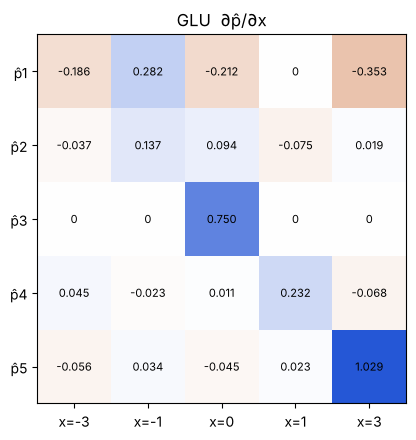

In [16]:
W = np.array([[ 0.8, -0.4,  0.3,  0.0,  0.5],
              [ 0.2,  0.6, -0.5,  0.4, -0.1],
              [-0.3,  0.5,  0.7, -0.2,  0.3],
              [ 0.4, -0.2,  0.1,  0.9, -0.6],
              [-0.5,  0.3, -0.4,  0.2,  0.6]])
x = EXAMPLE_Y_HAT.copy()

y_hat = W @ x                      # one row of Ŷ = XWᵀ
gate = sigmoid(y_hat)
glu_jacobian = np.diag(gate) + np.diag(x * sigmoid_grad(y_hat)) @ W

print("ŷ  =", y_hat.round(3))
print("σ(ŷ) =", gate.round(3))
print("σ′(ŷ) =", sigmoid_grad(y_hat).round(3))
print("\nGLU Jacobian ∂p̂/∂x (rows p̂ᵢ, columns xⱼ):")
print(glu_jacobian.round(3))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
plot_jacobian(ax, glu_jacobian, [f"p̂{i + 1}" for i in range(5)],
              [f"x={v:g}" for v in x], "GLU  ∂p̂/∂x")
plt.tight_layout()
plt.show()

## Slide 20 · SwiGLU: SiLU as the gate

SwiGLU is P̂ = SiLU(XWᵀ) ⊙ XVᵀ. A GLU-style layer has three weight matrices (W, V, W_out) instead of two, so the hidden size is cut to 2/3 to keep the parameter count equal. *From the paper:* 3072 → 2048 in the T5 experiments of Shazeer (2020); the cell checks the arithmetic.

In [17]:
d_model = 768
hidden_ffn = 3072
hidden_glu = 2048

print("2/3 * 3072 =", 2 / 3 * hidden_ffn)
print("ungated FFN params (W_in, W_out):  2 * 768 * 3072 =", 2 * d_model * hidden_ffn)
print("GLU-variant params (W, V, W_out):  3 * 768 * 2048 =", 3 * d_model * hidden_glu)

2/3 * 3072 = 2048.0
ungated FFN params (W_in, W_out):  2 * 768 * 3072 = 4718592
GLU-variant params (W, V, W_out):  3 * 768 * 2048 = 4718592


## Slide 21 · Do we really need the nonlinear activation?

Remove σ from the gate and you get the bilinear layer p̂ₖ = (x · wₖ)(x · vₖ). Each factor is linear in x, but their product is not, as the 1-D picture shows.

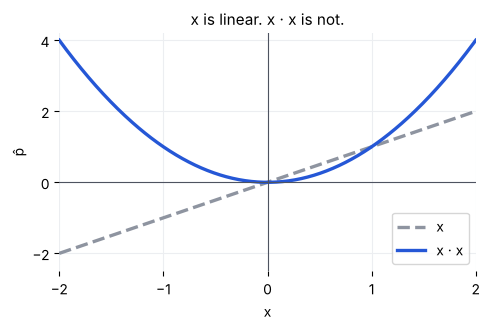

In [18]:
fig, ax = plt.subplots(figsize=(5, 3.4))
plot_curve(ax, identity, -2, 2, GREY, label="x", dashed=True)
plot_curve(ax, np.square, -2, 2, BLUE, label="x · x")
style_axes(ax, (-2, 2), (-2.5, 4.2), [-2, -1, 0, 1, 2], [-2, 0, 2, 4], "x is linear. x · x is not.", ylabel="p̂")
ax.set_xlabel("x")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Slide 22 · How much does the nonlinearity add? (Shazeer 2020 results)

*From the paper:* held-out log-perplexity of T5 base on C4 (lower is better), parameters and compute matched, from Shazeer (2020), *GLU Variants Improve Transformer*, arXiv:2002.05202, Table 1. The paper's "Swish" is SiLU. The "vs ReLU" column and the slide's "bilinear gets ≈ 70% of SwiGLU's gain" are computed from the table.

In [19]:
# Shazeer (2020), Table 1 (cited values, not computed)
shazeer = pd.DataFrame(
    [("GEGLU",           1.942, 0.004, 1.633),
     ("SwiGLU",          1.944, 0.010, 1.636),
     ("ReGLU",           1.953, 0.003, 1.645),
     ("Bilinear (no σ)", 1.960, 0.005, 1.648),
     ("GLU",             1.982, 0.006, 1.663),
     ("ReLU (baseline)", 1.997, 0.005, 1.677),
     ("GELU",            1.983, 0.005, 1.679),
     ("SiLU (Swish)",    1.994, 0.003, 1.683)],
    columns=["feed-forward layer", "65,536 steps", "sd", "524,288 steps"],
).set_index("feed-forward layer")

relu_baseline = shazeer.loc["ReLU (baseline)", "524,288 steps"]
shazeer["vs ReLU"] = shazeer["524,288 steps"] - relu_baseline
print(shazeer.round(3).to_string())

bilinear_gain = relu_baseline - shazeer.loc["Bilinear (no σ)", "524,288 steps"]
swiglu_gain = relu_baseline - shazeer.loc["SwiGLU", "524,288 steps"]
print(f"\nBilinear gain {bilinear_gain:.3f} of SwiGLU gain {swiglu_gain:.3f} = {bilinear_gain / swiglu_gain:.1%}")

                    65,536 steps     sd  524,288 steps  vs ReLU
feed-forward layer                                             
GEGLU                      1.942  0.004          1.633   -0.044
SwiGLU                     1.944  0.010          1.636   -0.041
ReGLU                      1.953  0.003          1.645   -0.032
Bilinear (no σ)            1.960  0.005          1.648   -0.029
GLU                        1.982  0.006          1.663   -0.014
ReLU (baseline)            1.997  0.005          1.677    0.000
GELU                       1.983  0.005          1.679    0.002
SiLU (Swish)               1.994  0.003          1.683    0.006

Bilinear gain 0.029 of SwiGLU gain 0.041 = 70.7%


## Slides 23–26 · Still being invented; SwiGLU in a feed-forward network and a residual MLP

Recap and architecture diagrams, no numbers. The quote on slide 23 ("we attribute their success, as all else, to divine benevolence") is from Shazeer (2020).

## Slides 27–29 · Mixture of experts: one gate per expert, top-k routing, keeping every expert in use

A mixture of experts applies the gating idea to whole feed-forward blocks: a router picks k experts per token, so only a small fraction of the weights is used for each token. The cell computes that fraction for the three models on slide 28.

*Illustrative:* the router gates g₁ = 0.7, g₂ = 0.3 (and top-1 keeping g₁ = 0.7) and the token counts 10/1/1 vs 4/4/4 are made-up examples. *From the papers / model releases:* the model sizes (Mixtral 8x7B: 2 of 8 experts, 47B total / 13B active; DeepSeek-V3: 8 of 256, 671B / 37B; Kimi K2: 8 of 384, 1T / 32B) and α = 0.01 in the load-balancing loss L = L_task + α · N · Σᵢ fᵢPᵢ (Switch Transformer, Fedus et al., 2022).

In [20]:
models = [
    ("Mixtral 8x7B", 47e9, 13e9),
    ("DeepSeek-V3", 671e9, 37e9),
    ("Kimi K2", 1e12, 32e9),
]
for name, total_params, active_params in models:
    print(f"{name:13} active / total = {active_params / 1e9:.0f}B / {total_params / 1e9:.0f}B = {active_params / total_params:.1%}")

Mixtral 8x7B  active / total = 13B / 47B = 27.7%
DeepSeek-V3   active / total = 37B / 671B = 5.5%
Kimi K2       active / total = 32B / 1000B = 3.2%
